# Assignment B1 : Uber Fare Prediction Using Machine Learning

## Objective
The objective of this project is to predict Uber ride fares based on pickup and drop-off coordinates and passenger count using machine learning regression algorithms.

## Algorithms Used
1. **Linear Regression** — a baseline regression model that estimates the relationship between input features and fare amount.
2. **Random Forest Regressor** — an ensemble learning algorithm that combines multiple decision trees to predict fare amounts.

## Project Workflow
1. Data loading and exploration
2. Data cleaning and preprocessing
3. Outlier removal
4. Exploratory data analysis and visualization
5. Feature selection and train-test splitting
6. Model training and prediction
7. Model evaluation and comparison
8. Feature importance analysis

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Dataset Loading and Exploration

The dataset contains historical Uber ride records. It includes fare amounts, pickup and drop-off coordinates, passenger counts, and other ride-related information.

The target variable is `fare_amount`, while the pickup and drop-off coordinates and passenger count are used as input features.

In this project, a sample of 50,000 records is used to reduce training time.

In [19]:
# Load dataset
df = pd.read_csv("uber.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [20]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
display(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

Statistical Summary:


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000



Column Names:
['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

Missing Values:


Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

## 2. Data Preprocessing

Data preprocessing improves data quality before model training.

The following operations are performed:

- Select a random sample of 50,000 rows for faster execution.
- Remove unnecessary columns such as `key` and `pickup_datetime`.
- Remove records containing missing values.
- Retain the numerical features required for fare prediction.

In [21]:
# Sample data for faster execution
df = df.sample(n=min(50000, len(df)), random_state=42).copy()

print("Shape after sampling:", df.shape)

# Drop unnecessary columns if present
df.drop(
    columns=["key", "pickup_datetime"],
    errors="ignore",
    inplace=True
)

# Remove missing values
df.dropna(inplace=True)

print("Shape after removing missing values:", df.shape)

display(df.head())

Shape after sampling: (50000, 9)
Shape after removing missing values: (50000, 7)


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
119737,187972,5.5,-74.000458,40.723990,-73.989682,40.725797,1
72272,4242034,45.0,0.000000,0.000000,0.000000,0.000000,5
158154,42897898,5.3,-73.955315,40.779068,-73.970558,40.764650,5
65426,16700122,32.3,-73.870920,40.773705,-73.964346,40.797100,3
30074,13592810,4.1,-73.992195,40.748958,-73.987078,40.743065,1


## 3. Outlier Detection and Removal

Outliers are observations that are unusually high, low, or invalid compared with typical records.

For this dataset, the following filters are applied:

- Fare amount between $0 and $200.
- Pickup and drop-off latitudes between 40.5 and 41.0.
- Pickup and drop-off longitudes between -74.5 and -73.5.
- Passenger count between 1 and 6.

The geographic filters approximately restrict the dataset to the New York City area. These thresholds are chosen for this assignment and may exclude some legitimate rides.

In [22]:
initial_rows = len(df)

df = df[
    (df["fare_amount"] >= 0) &
    (df["fare_amount"] <= 200) &
    (df["pickup_latitude"].between(40.5, 41.0)) &
    (df["pickup_longitude"].between(-74.5, -73.5)) &
    (df["dropoff_latitude"].between(40.5, 41.0)) &
    (df["dropoff_longitude"].between(-74.5, -73.5)) &
    (df["passenger_count"].between(1, 6))
].copy()

print("Rows before outlier removal:", initial_rows)
print("Rows after outlier removal:", len(df))
print("Rows removed:", initial_rows - len(df))

Rows before outlier removal: 50000
Rows after outlier removal: 48764
Rows removed: 1236


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of Fare Amounts

A histogram is used to understand the distribution of Uber fare amounts. The distribution helps identify common fare ranges and whether the target variable is skewed.

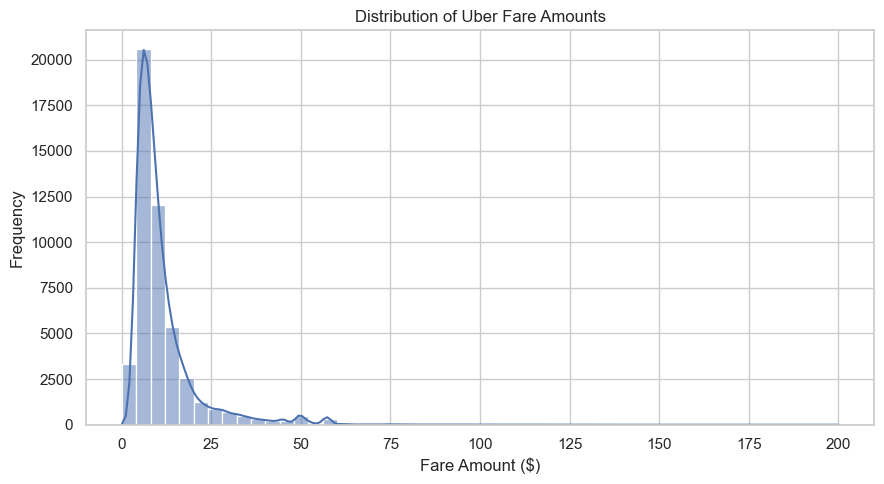

In [23]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="fare_amount",
    bins=50,
    kde=True
)

plt.title("Distribution of Uber Fare Amounts")
plt.xlabel("Fare Amount ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 4.2 Correlation Heatmap

A correlation matrix measures the strength and direction of linear relationships between numerical variables.

The heatmap helps identify which features are linearly associated with fare amount. Correlation does not necessarily imply causation, and weak linear correlation does not rule out nonlinear relationships.

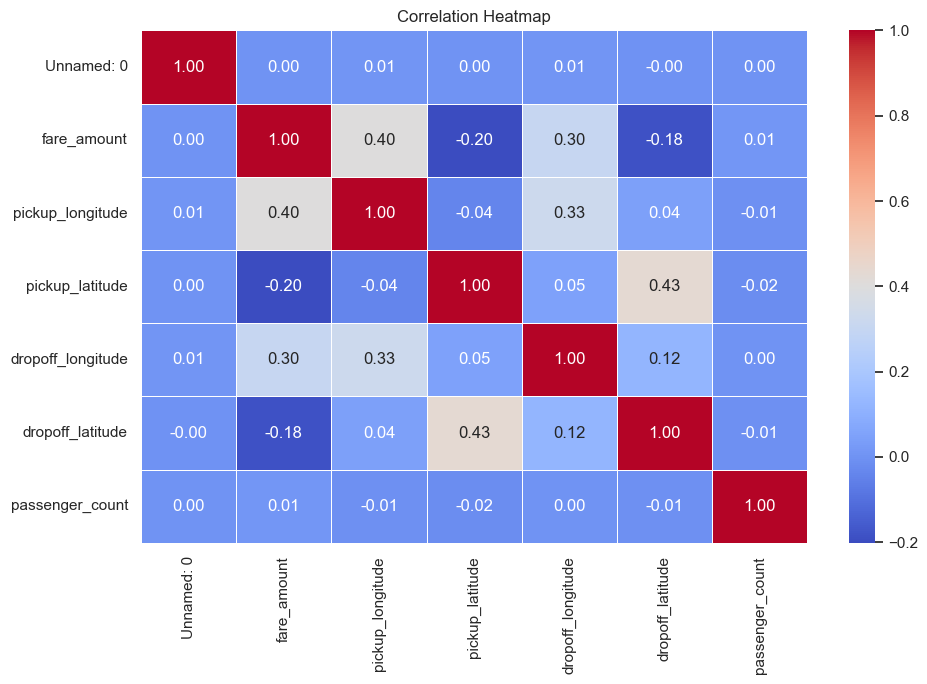

,fare_amount
fare_amount,1.000000
pickup_longitude,0.401123
dropoff_longitude,0.303551
passenger_count,0.011716
Unnamed: 0,0.001163
dropoff_latitude,-0.183574
pickup_latitude,-0.201744


In [24]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

display(
    correlation_matrix[["fare_amount"]]
    .sort_values(by="fare_amount", ascending=False)
)

## 5. Feature Selection and Train-Test Split

The features selected for prediction are:

- `pickup_longitude`
- `pickup_latitude`
- `dropoff_longitude`
- `dropoff_latitude`
- `passenger_count`

The target variable is `fare_amount`.

The dataset is divided into:
- **80% training data** to train the models.
- **20% testing data** to evaluate predictions on unseen records.

A fixed random state makes the split reproducible.

In [25]:
feature_columns = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count"
]

X = df[feature_columns]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (39011, 5)
Testing features: (9753, 5)
Training target: (39011,)
Testing target: (9753,)


### 5.1 Feature Scaling

StandardScaler transforms each feature to approximately zero mean and unit variance based on the training data.

The scaler is fitted only on the training data to prevent information leakage from the test set.

Feature scaling is useful for Linear Regression workflows and is generally not necessary for tree-based models such as Random Forest. For simplicity, both models below use the same scaled feature inputs.

In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


## 6. Model 1 — Linear Regression

Linear Regression models the relationship between input features and the target variable using a linear equation.

It is used as a baseline model to estimate Uber fare amounts from the selected ride features.

In [27]:
lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

lr_train_pred = lr_model.predict(X_train_scaled)
lr_test_pred = lr_model.predict(X_test_scaled)

lr_r2_train = r2_score(y_train, lr_train_pred)
lr_r2_test = r2_score(y_test, lr_test_pred)

lr_rmse_train = np.sqrt(mean_squared_error(y_train, lr_train_pred))
lr_rmse_test = np.sqrt(mean_squared_error(y_test, lr_test_pred))

print("Linear Regression Results")
print("-" * 35)
print(f"Training R² Score: {lr_r2_train:.4f}")
print(f"Testing R² Score:  {lr_r2_test:.4f}")
print(f"Training RMSE:     ${lr_rmse_train:.4f}")
print(f"Testing RMSE:      ${lr_rmse_test:.4f}")

Linear Regression Results
-----------------------------------
Training R² Score: 0.2548
Testing R² Score:  0.2647
Training RMSE:     $8.3471
Testing RMSE:      $8.2540


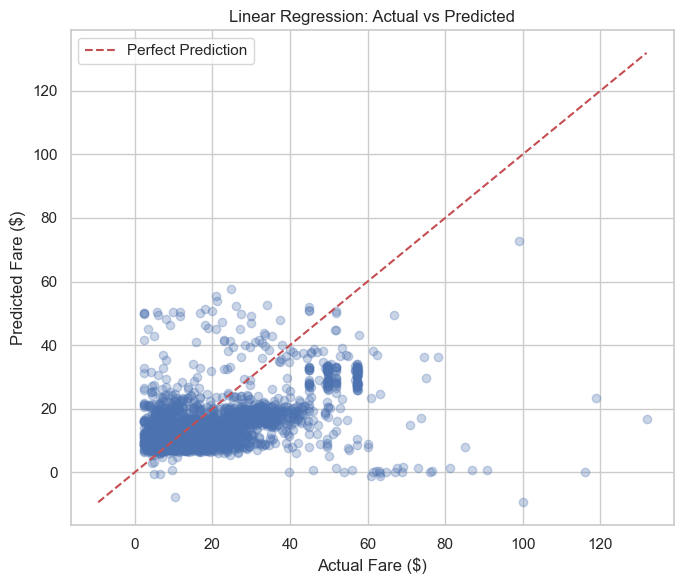

In [28]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, lr_test_pred, alpha=0.3)

min_val = min(y_test.min(), lr_test_pred.min())
max_val = max(y_test.max(), lr_test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Fare ($)")
plt.ylabel("Predicted Fare ($)")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Model 2 — Random Forest Regressor

Random Forest is an ensemble learning algorithm that trains multiple decision trees and combines their predictions.

It can learn nonlinear relationships between ride features and fare amounts. The parameters below limit the number and depth of trees to reduce training time.

In [29]:
rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

rf_train_pred = rf_model.predict(X_train_scaled)
rf_test_pred = rf_model.predict(X_test_scaled)

rf_r2_train = r2_score(y_train, rf_train_pred)
rf_r2_test = r2_score(y_test, rf_test_pred)

rf_rmse_train = np.sqrt(mean_squared_error(y_train, rf_train_pred))
rf_rmse_test = np.sqrt(mean_squared_error(y_test, rf_test_pred))

print("Random Forest Results")
print("-" * 35)
print(f"Training R² Score: {rf_r2_train:.4f}")
print(f"Testing R² Score:  {rf_r2_test:.4f}")
print(f"Training RMSE:     ${rf_rmse_train:.4f}")
print(f"Testing RMSE:      ${rf_rmse_test:.4f}")

Random Forest Results
-----------------------------------
Training R² Score: 0.7930
Testing R² Score:  0.7353
Training RMSE:     $4.3999
Testing RMSE:      $4.9529


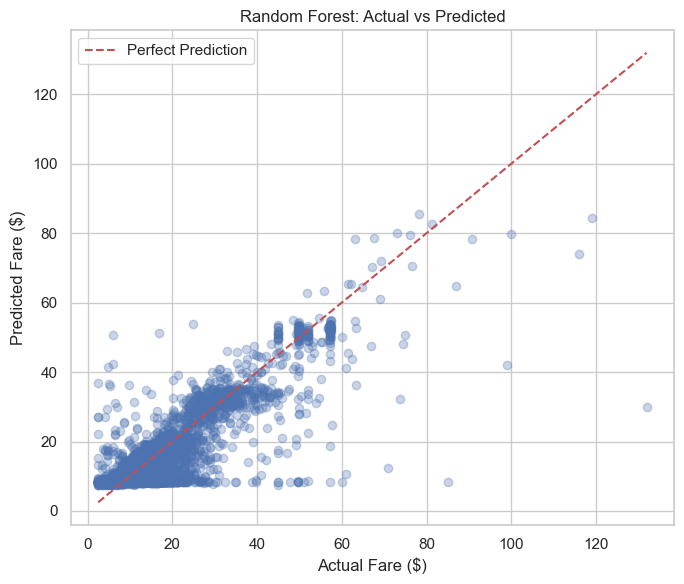

In [30]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, rf_test_pred, alpha=0.3)

min_val = min(y_test.min(), rf_test_pred.min())
max_val = max(y_test.max(), rf_test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Fare ($)")
plt.ylabel("Predicted Fare ($)")
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Model Evaluation and Comparison

The two models are evaluated using two metrics:

- **R² Score:** Measures how well the model explains variation in fare amounts. A higher score is generally better.
- **Root Mean Squared Error (RMSE):** Measures the typical prediction error while penalizing larger errors more strongly. A lower score is better.

Training metrics show performance on data used for learning, while testing metrics indicate generalization to unseen data.

,Model,Train R2,Test R2,Train RMSE,Test RMSE
0,Linear Regression,0.2548,0.2647,8.3471,8.2540
1,Random Forest,0.7930,0.7353,4.3999,4.9529


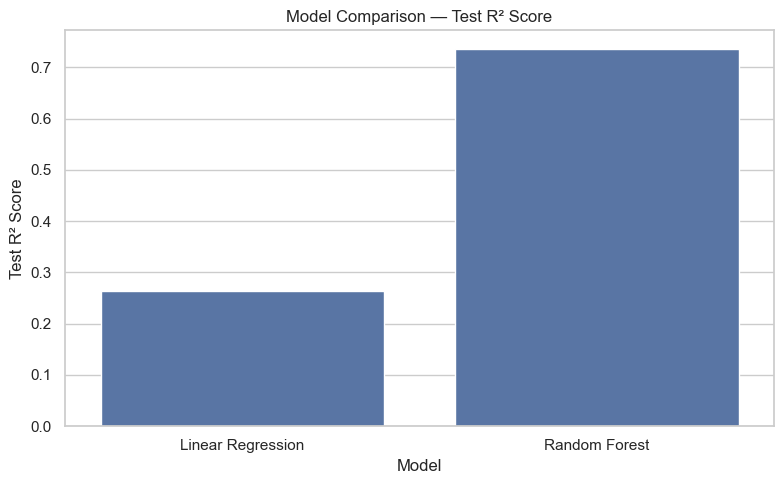

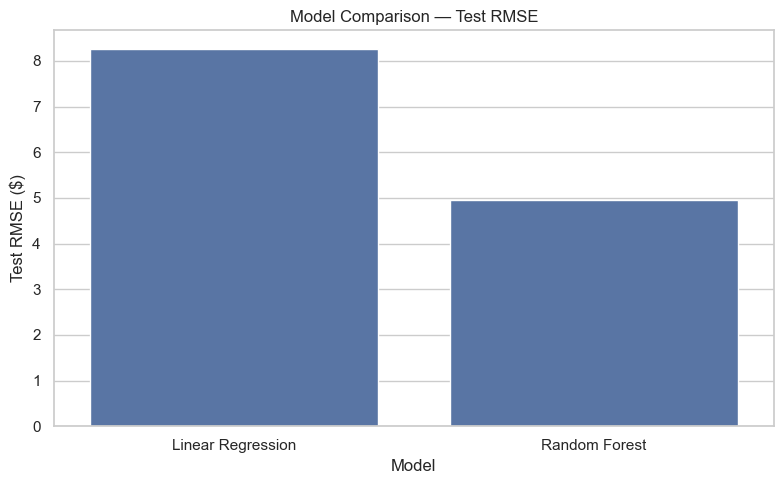

In [31]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Train R2": [lr_r2_train, rf_r2_train],
    "Test R2": [lr_r2_test, rf_r2_test],
    "Train RMSE": [lr_rmse_train, rf_rmse_train],
    "Test RMSE": [lr_rmse_test, rf_rmse_test]
})

display(comparison.round(4))

# Compare test R²
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Test R2"
)

plt.title("Model Comparison — Test R² Score")
plt.ylabel("Test R² Score")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

# Compare test RMSE
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Test RMSE"
)

plt.title("Model Comparison — Test RMSE")
plt.ylabel("Test RMSE ($)")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

## 9. Feature Importance Analysis

Random Forest estimates feature importance based on how much each feature contributes to reducing prediction error across the decision trees.

The feature importance scores help us understand which input variables are most influential in the trained model. These scores describe the model's behavior and should not be interpreted as proof of causal relationships.

,Feature,Importance
2,dropoff_longitude,0.467253
0,pickup_longitude,0.325495
3,dropoff_latitude,0.111997
1,pickup_latitude,0.093251
4,passenger_count,0.002004


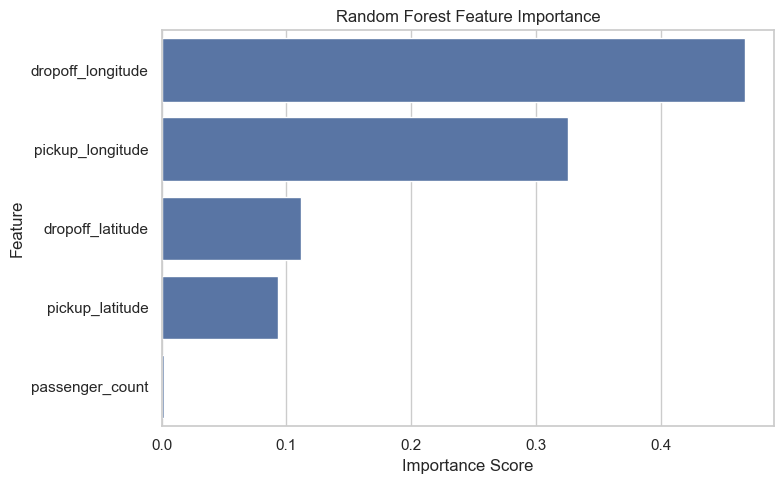

In [32]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()